In [1]:
import warnings
warnings.filterwarnings('ignore')

from rtree import index
import numpy as np
import pandas as pd
import glob
import os.path as osp
import xarray as xr
import logging
import gsw
import matplotlib.pyplot as plt
import numpy as np
import pickle
from matplotlib import ticker
from scipy.interpolate import griddata

from scaloa import *
import utils as ut

In [2]:
cases = {
    'SANAGU2022_sanagu14_extended': ['G'],
    'SANAGU2022_sanagu15_extended': ['G'],
}

xcorr=180000
ycorr=25

dict_with_sections = {}
for case in cases:
    print(case)
    # refdict = ut.get_dict('configs.dict')
    refdict = ut.get_dict('configs_section.dict')
    refdict = refdict[case]

    ctdpath      = refdict['path.cnv2nc']
    reftab_path  = refdict['path.cnv2nc_reftab']
    bathy_path  = refdict['path.bathy']
    reftab_dict  = refdict['reference_table_dict_oa']
    reference_table=['lon_coast', 'lat_coast']

    ncbathy = xr.open_dataset(bathy_path)

    secids = cases[case]

    for secid in secids:
        df = prepare_reference_table(reftab_path, ctdpath=ctdpath, **reftab_dict)

        # -- prepare table -- #
        df1, dfg = read_section(df, section=secid, reference_table=reference_table)

        # cap depth in 500 meters depth
        df1 = df1[df1['depSM'] <= 300]
        # -- prepare bathymetry data for masking -- #
        lon = df1['lon'].values
        lat = df1['lat'].values
        dist = df1['dist'].values
        l = sorted(list(set(zip(lon,lat,dist))))
        dlon, dlat, ddst, depth = lonlatdepth_extend(ncbathy, lon, lat, dist, n=20, dataset='gebco2019',varname='elevation')
        # df1.index *= 800
        # -- objective analysis -- #
        xm, ym, sa ,errsa, df2sa = get_trend_correction_oa(df1,'sa', corrlenx=xcorr, corrleny=ycorr, err_thresh=0.01)
        xm, ym, ct ,errct, df2ct = get_trend_correction_oa(df1,'ct', corrlenx=xcorr, corrleny=ycorr, err_thresh=0.01)

        df1['sigma'] = gsw.sigma0(df1['sa'], df1['ct'])
        xm, ym, sg, _, df2sig = get_trend_correction_oa(df1,'sigma', corrlenx=xcorr, corrleny=ycorr, err_thresh=0.01)

        # -- plotting -- #
        ylimdict = {
            'F': (200, 4.0),
            'G': (200, 4.0),
            'H': (200, 4.0),
        }

        cdicts = ut.colordicts()
        cdicts['sal']['oa'] = sa
        cdicts['temp']['oa'] = ct
        cdicts['sigmaT']['oa'] = sg
        cdicts['sal']['data'] = df1['sa']
        cdicts['temp']['data'] = df1['ct']
        cdicts['sigmaT']['data'] = df1['sigma']
        cdicts['sal']['err'] = errsa
        cdicts['temp']['err'] = errsa

        cdicts['temp']['contour'] = [18,20,22,24]
        cdicts['temp']['vmax'] = 30
        cdicts['temp']['vmin'] = 12
        cdicts['temp']['deltav'] = 0.1

        cdicts['sal']['contour'] = [35,36,37,38]
        cdicts['sal']['vmax'] = 38
        cdicts['sal']['vmin'] = 34
        cdicts['sal']['deltav'] = 0.1

        cdicts['sigmaT']['contour'] = [25, 25.5]

        # changing colormaps for salt and temp
        import cmocean.cm as cmo
        cdicts['sal']['cmap'] = cmo.haline
        cdicts['temp']['cmap'] = cmo.thermal

        # coordinates variables
        cdicts['sal']['xm'] = xm
        cdicts['sal']['ym'] = ym
        cdicts['sal']['depth'] = depth
        cdicts['sal']['ddst'] = ddst
        cdicts['sal']['dlon'] = dlon
        cdicts['sal']['dlat'] = dlat
        cdicts['sal']['dist'] = dist

        cdicts['temp']['xm'] = xm
        cdicts['temp']['ym'] = ym
        cdicts['temp']['depth'] = depth
        cdicts['temp']['ddst'] = ddst
        cdicts['temp']['dlon'] = dlon
        cdicts['temp']['dlat'] = dlat
        cdicts['temp']['dist'] = dist

        cdicts['secid'] = secid
        cdicts['case'] = case
        cdicts['time'] = f"{df1['time'].astype('datetime64[ns]').dt.date.min().strftime('%d')} to {df1['time'].astype('datetime64[ns]').dt.date.max().strftime('%d %m/%Y')}"

        cdicts['l'] = l
        dict_with_sections[f"{case}_{secid}"] = cdicts

SANAGU2022_sanagu14_extended
SANAGU2022_sanagu15_extended


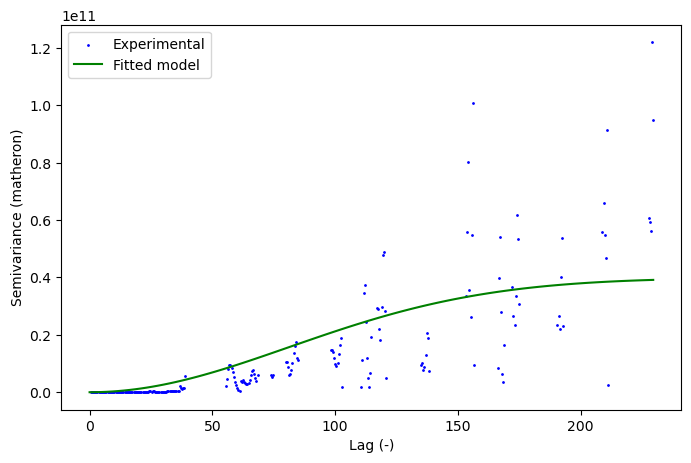

In [3]:
from skgstat import Variogram
import numpy as np

# bin_edges = np.arange(0, 2.2e5, 2e4)

# aux = dict_with_sections['SANAGU2022_sanagu14_extended_G']['sal']
aux1 = df2ct[['ct_detrend', 'dist']]

coords = np.array((aux1['dist']/1e3, aux1['dist'].index/10))
values = aux1

V = Variogram(coords.T, values, model='gaussian', n_lags=500, maxlag=260)
# V.plot()

# If gray horizontal lines still appear, create custom plot:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(V.bins, V.experimental, s=1, color='blue', label='Experimental')

# Plot the fitted model
x = np.linspace(0, V.bins[-1], 100)
y = V.fitted_model(x)
ax.plot(x, y, 'g-', label='Fitted model')

ax.set_xlabel('Lag (-)')
ax.set_ylabel('Semivariance (matheron)')
ax.legend()
plt.show()

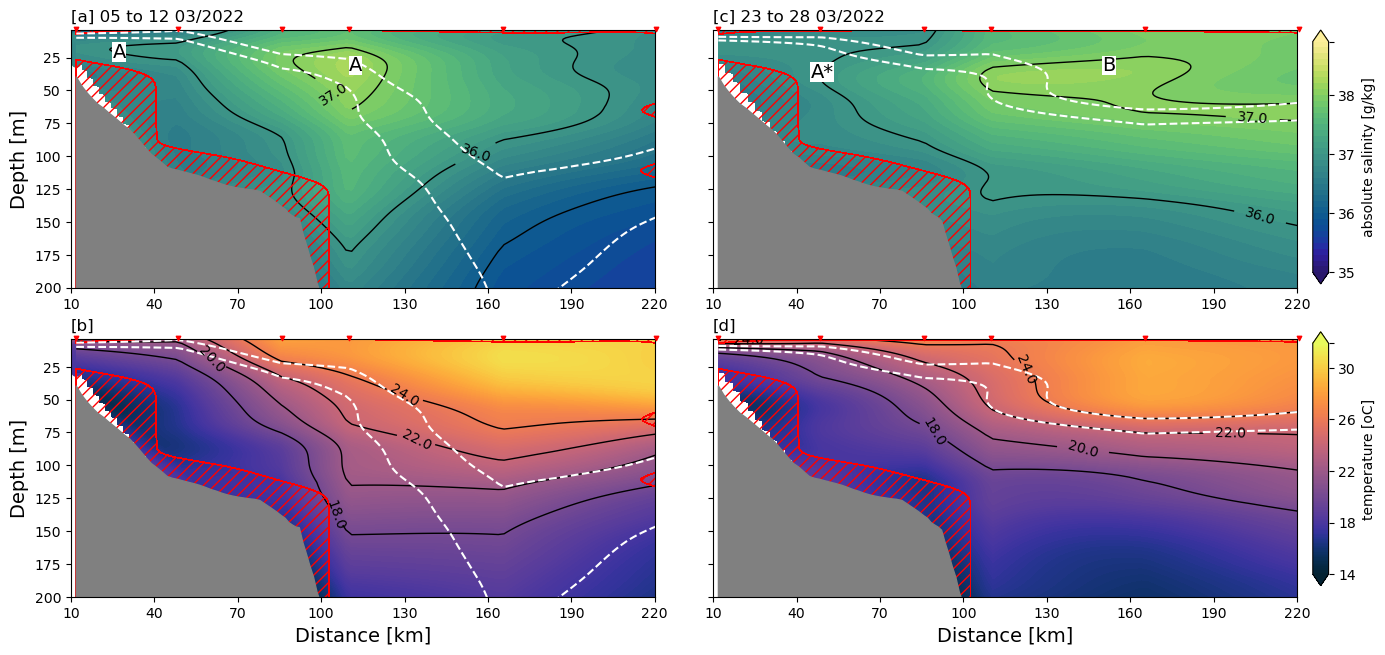

In [5]:
fig,axes = plt.subplots(figsize=[7.91*2, 7.36], nrows=2, ncols=2, sharey=True)

#### PLOTTING SANAGU14 ####
cdicts = dict_with_sections['SANAGU2022_sanagu14_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']

fig, axes[0,0], _ = subroutine_TSsection(cdicts['sal'], cdicts['l'], ylimdict[secid], fig=fig, 
                                         ax=axes[0,0], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,0], _ = subroutine_TSsection(cdicts['temp'], cdicts['l'], ylimdict[secid], fig=fig, 
                                         ax=axes[1,0], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)


axes[0,0].scatter(cdicts['sal']['dist']/1e3, cdicts['sal']['data'].index, c=cdicts['sal']['data'],
                 cmap=cdicts['sal']['cmap'],
                  vmin=cdicts['sal']['vmin'], vmax=cdicts['sal']['vmax'], zorder=0)

axes[1,0].scatter(cdicts['sal']['dist']/1e3, cdicts['sal']['data'].index, c=cdicts['temp']['data'],
                 cmap=cdicts['temp']['cmap'],
                  vmin=cdicts['temp']['vmin'], vmax=cdicts['temp']['vmax'], zorder=0)


cr = axes[0,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

cr = axes[1,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,0].set_title(f'[a] {time_str}', loc='left')
axes[1,0].set_title('[b]', loc='left')
# axes[0,0].set_title(time_str, loc='right')
# axes[1,0].set_title(f'Section {secid}', loc='right')
axes[1,0].set_xlabel('Distance [km]', fontsize=14)
axes[0,0].set_ylabel('Depth [m]', fontsize=14)
axes[0,0].set_ylim(ylimdict[secid])
axes[1,0].set_ylim(ylimdict[secid])

axes[0,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))
axes[1,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))

#### PLOTTING SANAGU15 ####
cdicts = dict_with_sections['SANAGU2022_sanagu15_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']



fig, axes[0,1], cfsalt = subroutine_TSsection(cdicts['sal'], cdicts['l'], ylimdict[secid], 
                                              fig=fig, ax=axes[0,1], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,1], cftemp = subroutine_TSsection(cdicts['temp'], cdicts['l'], ylimdict[secid], 
                                              fig=fig, ax=axes[1,1], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)

cr = axes[0,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section
cr = axes[1,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,1].set_title(f'[c] {time_str}', loc='left')
axes[1,1].set_title('[d]', loc='left')
# axes[0,1].set_title(time_str, loc='right')
# axes[1,1].set_title(f'Section {secid}', loc='right')
axes[1,1].set_xlabel('Distance [km]', fontsize=14)
axes[1,0].set_ylabel('Depth [m]', fontsize=14)
axes[0,1].set_ylim(ylimdict[secid])
axes[1,1].set_ylim(ylimdict[secid])

_ = [ax.set_ylabel('') for ax in [axes[0,1],axes[1,1]]]

#### adding colorbar for each variable
cbaxes = fig.add_axes([0.91, 0.535, 0.01, 0.345])
cbar_salt = plt.colorbar(cfsalt, cax=cbaxes)
cbar_salt.set_label('absolute salinity [g/kg]')

tick_locator = ticker.MaxNLocator(nbins=4)
cbar_salt.locator = tick_locator
cbar_salt.update_ticks()

cbar_salt.ax.set_yticklabels([35, 36, 37, 38])

cbaxes = fig.add_axes([0.91, 0.125, 0.01, 0.345])
cbar_temp = plt.colorbar(cftemp, cax=cbaxes)
cbar_temp.set_label('temperature [oC]')

tick_locator = ticker.MaxNLocator(nbins=5)
cbar_temp.locator = tick_locator
cbar_temp.update_ticks()

cbar_temp.ax.set_yticklabels([14, 18, 22, 26, 30])

fig.patch.set_alpha(1.0)
plt.subplots_adjust(wspace=.1)

# making sure both transect has the same x-axis (ticks and limits) to allow comparison
_ = [ax.set_xticks(np.arange(10,250, 30)) for ax in axes.ravel()]
_ = [ax.set_xlim([10,220]) for ax in axes.ravel()]

ax = axes.ravel()[0]
ax.text(25, 25, 'A', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)
ax.text(110, 35, 'A', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)

ax = axes.ravel()[1]
ax.text(45, 40, 'A*', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)
ax.text(150, 35, 'B', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)
# ax.text(200, 80, 'B', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)

plt.savefig('../figures/manuscript/00_manuscript_cruise_transects_new.png', bbox_inches="tight", dpi=300)

In [ ]:
!pwd

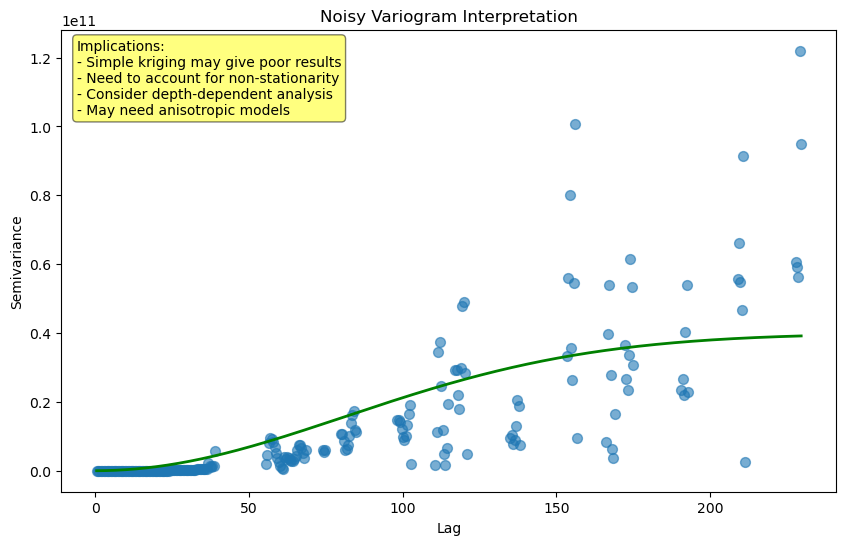

In [6]:
# The noisy fit suggests:
fig, ax = plt.subplots(figsize=(10, 6))

# Show the variogram with annotations
ax.scatter(V.bins, V.experimental, s=50, alpha=0.6)
ax.plot(V.bins, V.fitted_model(V.bins), 'g-', linewidth=2)

# Annotate problem areas
ax.annotate('High scatter = mixing different processes', 
            xy=(150000, 1.2), xytext=(180000, 1.5),
            arrowprops=dict(arrowstyle='->', color='red'))

ax.annotate('Poor fit = single model insufficient', 
            xy=(250000, 0.8), xytext=(280000, 0.5),
            arrowprops=dict(arrowstyle='->', color='red'))

ax.set_xlabel('Lag')
ax.set_ylabel('Semivariance')
ax.set_title('Noisy Variogram Interpretation')

# Add text box with implications
textstr = """Implications:
- Simple kriging may give poor results
- Need to account for non-stationarity
- Consider depth-dependent analysis
- May need anisotropic models"""
props = dict(boxstyle='round', facecolor='yellow', alpha=0.5)
ax.text(0.02, 0.98, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

plt.show()

In [10]:
_, _, _, _, df2 = get_trend_correction_oa(df1,'sa', corrlenx=xcorr, corrleny=ycorr, err_thresh=0.01)
df2

,sa,dist,station,sa_trend,sa_detrend
index,,,,,
4.0,35.304427,11906.654286,SANAGU15_G1_CTD_2_OT,35.663957,-0.359530
5.0,35.416479,11906.654286,SANAGU15_G1_CTD_2_OT,35.674680,-0.258201
6.0,35.490146,11906.654286,SANAGU15_G1_CTD_2_OT,35.685404,-0.195258
7.0,35.542428,11906.654286,SANAGU15_G1_CTD_2_OT,35.696128,-0.153700
8.0,35.623860,11906.654286,SANAGU15_G1_CTD_2_OT,35.706852,-0.082992
...,...,...,...,...,...
295.0,35.551508,276148.350307,SANAGU15_G7_CTD_2_OT,35.325285,0.226223
296.0,35.549110,276148.350307,SANAGU15_G7_CTD_2_OT,35.318916,0.230194
297.0,35.544555,276148.350307,SANAGU15_G7_CTD_2_OT,35.312546,0.232009


Horizontal range: 3632.1 m
Vertical range: 71.5 m
Anisotropy ratio: 50.8


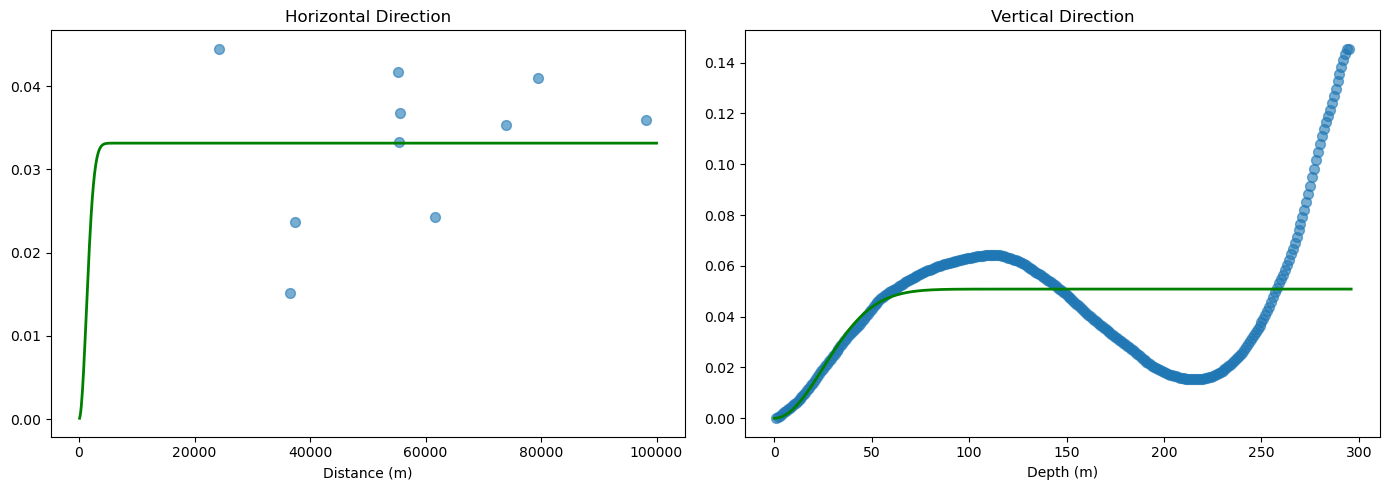

In [12]:
from skgstat import DirectionalVariogram

aux = dict_with_sections['SANAGU2022_sanagu14_extended_G']['sal']
aux1 = df2['sa_detrend']



coords = np.array((df2['dist'], df2['dist'].index))
values = aux1

# Add small noise to coordinates for DirectionalVariogram to work
coords_noisy = coords.T.copy()
# coords_noisy[:, 0] += np.random.normal(0, 1000, len(coords_noisy))  # Small noise relative to scale
# coords_noisy[:, 1] += np.random.normal(0.01, 0.02, len(coords_noisy))

# Horizontal variogram (0°)
h_vario = DirectionalVariogram(
    coords_noisy, values,
    azimuth=0,
    tolerance=40,
    bandwidth=200000,  # Narrow bandwidth to exclude vertical pairs
    n_lags=1000,
    maxlag=100000,
    model='gaussian'
)

# Vertical variogram (90°)
v_vario = DirectionalVariogram(
    coords_noisy, values,
    azimuth=90,
    tolerance=40,
    bandwidth=10,  # Narrow bandwidth to exclude horizontal pairs
    n_lags=10000,
    model='gaussian'
)

# Plot both
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(h_vario.bins, h_vario.experimental, s=50, alpha=0.6)
ax1.plot(h_vario.bins, h_vario.fitted_model(h_vario.bins), 'g-', linewidth=2)
# Horizontal
# h_vario.plot(axes=ax1)
ax1.set_title('Horizontal Direction')
ax1.set_xlabel('Distance (m)')

# Vertical


ax2.scatter(v_vario.bins, v_vario.experimental, s=50, alpha=0.6)
ax2.plot(v_vario.bins, v_vario.fitted_model(v_vario.bins), 'g-', linewidth=2)
# Horizontal
# h_vario.plot(axes=ax1)
ax2.set_title('Horizontal Direction')
ax2.set_xlabel('Distance (m)')

ax2.set_title('Vertical Direction')
ax2.set_xlabel('Depth (m)')

# Calculate anisotropy
h_range = h_vario.describe()['effective_range']
v_range = v_vario.describe()['effective_range']
print(f"Horizontal range: {h_range:.1f} m")
print(f"Vertical range: {v_range:.1f} m")
print(f"Anisotropy ratio: {h_range/v_range:.1f}")

plt.tight_layout()
plt.show()